In [62]:
import cv2
import numpy as np
from ultralytics import YOLO
from collections import defaultdict, deque # Memory structures for tracking
import matplotlib.pyplot as plt

# COORDINATES SELECTION

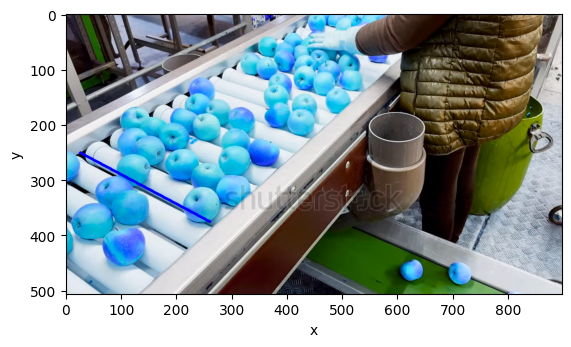

In [10]:
line_points = [(25, 250), (260, 375)]

def draw_line(frame, line_points):

    cv2.line(frame, line_points[0], line_points[1], (0, 0, 255), 4)
    return frame

frame = cv2.imread('/home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/Video/frames/frame_0.png')

frame_line = draw_line(frame, line_points)

plt.figure()
plt.imshow(frame)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

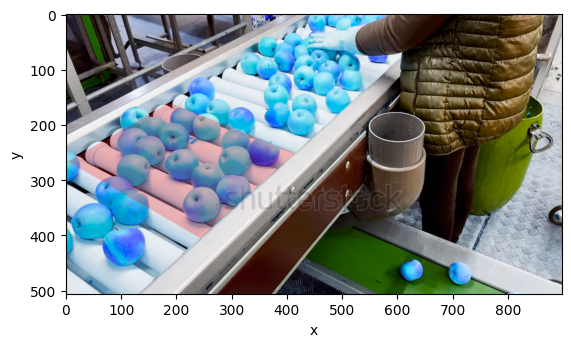

In [41]:
roi_points = [(4,266), (186,160), (413,251), (242,404)]

def draw_roi(frame, points, color):

    overlay = frame.copy()
    cv2.fillPoly(overlay, [np.array(points, np.int32)], color)

    # BLEND THE OVERLAY WITH THE ORIGINAL FRAME
    # 0.25 TRANSPARENCY OF THE OVERLAY (ROI COLOR)
    # 0.75 TRANSPARENCY OF THE ORIGINAL FRAME
    # 0 GAMMA VALUE (BRIGHTNESS ADJUSTMENT)

    return cv2.addWeighted(overlay, 0.25, frame, 0.75, 0)

frame = cv2.imread('/home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/Video/frames/frame_0.png')

frame_line = draw_roi(frame, roi_points, (255, 0, 0))

plt.figure()
plt.imshow(frame_line)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

# REAL-TIME PROCESSING

In [57]:
model = YOLO('/home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/runs/detect/apple_datasets_yolov11/weights/best.pt')

cap = cv2.VideoCapture('/home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/Video/mp4/input_video.mp4')

In [58]:
# STORES LAST 10 CENTER POINTS FOR EACH TRACKED POINT
center_history = defaultdict(lambda: deque(maxlen=10))

# STORES PREVIOUS CENTER FOR LINE CROSSING COMPARISON
previous_center = {}

In [59]:
# CENTER SMOOTHING FUNCTION

#'''
def get_smooth_center(track_id, new_center):

    center_history[track_id].append(new_center)

    # X, Y SEPARATION
    xs = [c[0] for c in center_history[track_id]]
    ys = [c[1] for c in center_history[track_id]]

    # AVERAGE X, Y
    avg_x = int(sum(xs)/len(xs))
    avg_y = int(sum(ys)/len(ys))

    return (avg_x, avg_y)
#'''

# LINE CROSSING FUNCTION

def is_center_crossing_line(prev_center, curr_center, line_p1, line_p2):

    x1, y1 = line_p1
    x2, y2 = line_p2

    px, py = prev_center
    cx, cy = curr_center

    # DETERMINE WHICH SIDE OF THE LINE EACH CENTER IS ON
    prev_side = ((x2-x1) * (py-y1) - (y2-y1) * (px-x1))
    curr_side = ((x2-x1) * (cy-y1) - (y2-y1) * (cx-x1))

    return prev_side * curr_side < 0

In [60]:
# ROI & LINE DRAWING FUNCTIONS

def draw_roi(frame, points, color):

    overlay = frame.copy()
    cv2.fillPoly(overlay, [np.array(points, np.int32)], color)

    # BLEND THE OVERLAY WITH THE ORIGINAL FRAME
    # 0.25 TRANSPARENCY OF THE OVERLAY (ROI COLOR)
    # 0.75 TRANSPARENCY OF THE ORIGINAL FRAME
    # 0 GAMMA VALUE (BRIGHTNESS ADJUSTMENT)

    return cv2.addWeighted(overlay, 0.25, frame, 0.75, 0)

def draw_line(frame, line_points):

    cv2.line(frame, line_points[0], line_points[1], (0, 0, 255), 4)
    return frame

In [61]:
# roi_points = [(8, 353), (411, 569), (702, 302), (323, 182)]
# line_points = [(161, 272), (546, 444)]
# roi_points = [(20, 250), (186,160), (413,251), (263,388)]
# roi_points = [(4,266), (186,160), (413,251), (242,404)]
roi_points = [(5,270), (121,148), (381,289), (242,422)]
line_points = [(25,250), (260, 375)]

apple_count = 0
counted_ids = set()

while True:

    ret, frame = cap.read()
    if not ret:
        break

    mask = np.zeros(frame.shape[:2], np.uint8)
    cv2.fillPoly(mask, [np.array(roi_points, np.int32)], 255)

    masked_frame = cv2.bitwise_and(frame, frame, mask=mask)

    # persist = True KEEPS TRACKING IDS CONSISTENT ACROSS FRAMES
    results = model.track(masked_frame, persist=True, verbose=False)[0]

    frame = draw_roi(frame, roi_points, (255, 0, 0))

    frame = draw_line(frame, line_points)

    for box in results.boxes:

        if box.id is None:
            continue

        track_id = int(box.id)

        x1, y1, x2, y2 = map(int, box.xyxy[0])

        raw_center = ((x1+x2)//2, (y1+y2)//2)

        smooth_center = get_smooth_center(track_id, raw_center)

        if track_id in previous_center and track_id not in counted_ids:

            crossed = is_center_crossing_line(
                previous_center[track_id],
                smooth_center,
                line_points[0],
                line_points[1]
            )

            if crossed:

                counted_ids.add(track_id)
                apple_count += 1

        previous_center[track_id] = smooth_center

        color = (0, 255, 0) if track_id not in counted_ids else (0,0, 255)
        cv2.circle(frame, smooth_center, 5, color, -1)
        cv2.putText(frame, f"{track_id}", (smooth_center[0]+5, smooth_center[1]-5), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)

    cv2.rectangle(frame, (5, 5), (220, 55), (0, 255, 255), -1)
    cv2.putText(frame, f"Count: {apple_count}", (10, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 0), 4)

    cv2.imshow("Object Counting", frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()